In [1]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

url = "https://raw.githubusercontent.com/sushantag9/Supermarket-Sales-Data-Analysis/master/supermarket_sales%20-%20Sheet1.csv"

df = pd.read_csv(url)

print("Dataset loaded successfully!")
print("Dataset Shape:", df.shape)

display(df.head())


Dataset loaded successfully!
Dataset Shape: (1000, 17)


,Invoice ID,Branch,City,Customer type,Gender,Product line,Unit price,Quantity,Tax 5%,Total,Date,Time,Payment,cogs,gross margin percentage,gross income,Rating
0,750-67-8428,A,Yangon,Member,Female,Health and beauty,74.69,7,26.1415,548.9715,1/5/2019,13:08,Ewallet,522.83,4.761905,26.1415,9.1
1,226-31-3081,C,Naypyitaw,Normal,Female,Electronic accessories,15.28,5,3.8200,80.2200,3/8/2019,10:29,Cash,76.40,4.761905,3.8200,9.6
2,631-41-3108,A,Yangon,Normal,Male,Home and lifestyle,46.33,7,16.2155,340.5255,3/3/2019,13:23,Credit card,324.31,4.761905,16.2155,7.4
3,123-19-1176,A,Yangon,Member,Male,Health and beauty,58.22,8,23.2880,489.0480,1/27/2019,20:33,Ewallet,465.76,4.761905,23.2880,8.4
4,373-73-7910,A,Yangon,Normal,Male,Sports and travel,86.31,7,30.2085,634.3785,2/8/2019,10:37,Ewallet,604.17,4.761905,30.2085,5.3


In [2]:

print("Dataset Information:")
df.info()

print("\nMissing Values:")
print(df.isnull().sum())

print("\nDuplicate Rows:", df.duplicated().sum())

print("\nStatistical Summary:")
display(df.describe())


Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 17 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Invoice ID               1000 non-null   object 
 1   Branch                   1000 non-null   object 
 2   City                     1000 non-null   object 
 3   Customer type            1000 non-null   object 
 4   Gender                   1000 non-null   object 
 5   Product line             1000 non-null   object 
 6   Unit price               1000 non-null   float64
 7   Quantity                 1000 non-null   int64  
 8   Tax 5%                   1000 non-null   float64
 9   Total                    1000 non-null   float64
 10  Date                     1000 non-null   object 
 11  Time                     1000 non-null   object 
 12  Payment                  1000 non-null   object 
 13  cogs                     1000 non-null   float64
 14  gros

,Unit price,Quantity,Tax 5%,Total,cogs,gross margin percentage,gross income,Rating
count,1000.000000,1000.000000,1000.000000,1000.000000,1000.00000,1.000000e+03,1000.000000,1000.00000
mean,55.672130,5.510000,15.379369,322.966749,307.58738,4.761905e+00,15.379369,6.97270
std,26.494628,2.923431,11.708825,245.885335,234.17651,6.131498e-14,11.708825,1.71858
min,10.080000,1.000000,0.508500,10.678500,10.17000,4.761905e+00,0.508500,4.00000
25%,32.875000,3.000000,5.924875,124.422375,118.49750,4.761905e+00,5.924875,5.50000
50%,55.230000,5.000000,12.088000,253.848000,241.76000,4.761905e+00,12.088000,7.00000
75%,77.935000,8.000000,22.445250,471.350250,448.90500,4.761905e+00,22.445250,8.50000
max,99.960000,10.000000,49.650000,1042.650000,993.00000,4.761905e+00,49.650000,10.00000


In [3]:

# Create a copy of the original dataset
df_clean = df.copy()

# Remove duplicate rows
df_clean = df_clean.drop_duplicates()

# Check missing values
print("Missing values before cleaning:")
print(df_clean.isnull().sum())

# Fill missing numerical values with median
for col in df_clean.select_dtypes(include=np.number).columns:
    df_clean[col] = df_clean[col].fillna(df_clean[col].median())

# Fill missing text values with mode
for col in df_clean.select_dtypes(include='object').columns:
    if df_clean[col].isnull().any():
        df_clean[col] = df_clean[col].fillna(df_clean[col].mode()[0])

# Convert Date and Time columns
df_clean['Date'] = pd.to_datetime(df_clean['Date'], errors='coerce')
df_clean['Time'] = pd.to_datetime(
    df_clean['Time'], format='%H:%M', errors='coerce'
).dt.time

print("\nData cleaning completed!")
print("Original shape:", df.shape)
print("Cleaned shape:", df_clean.shape)

print("\nMissing values after cleaning:")
print(df_clean.isnull().sum())

display(df_clean.head())


Missing values before cleaning:
Invoice ID                 0
Branch                     0
City                       0
Customer type              0
Gender                     0
Product line               0
Unit price                 0
Quantity                   0
Tax 5%                     0
Total                      0
Date                       0
Time                       0
Payment                    0
cogs                       0
gross margin percentage    0
gross income               0
Rating                     0
dtype: int64

Data cleaning completed!
Original shape: (1000, 17)
Cleaned shape: (1000, 17)

Missing values after cleaning:
Invoice ID                 0
Branch                     0
City                       0
Customer type              0
Gender                     0
Product line               0
Unit price                 0
Quantity                   0
Tax 5%                     0
Total                      0
Date                       0
Time                       0
Pay

,Invoice ID,Branch,City,Customer type,Gender,Product line,Unit price,Quantity,Tax 5%,Total,Date,Time,Payment,cogs,gross margin percentage,gross income,Rating
0,750-67-8428,A,Yangon,Member,Female,Health and beauty,74.69,7,26.1415,548.9715,2019-01-05,13:08:00,Ewallet,522.83,4.761905,26.1415,9.1
1,226-31-3081,C,Naypyitaw,Normal,Female,Electronic accessories,15.28,5,3.8200,80.2200,2019-03-08,10:29:00,Cash,76.40,4.761905,3.8200,9.6
2,631-41-3108,A,Yangon,Normal,Male,Home and lifestyle,46.33,7,16.2155,340.5255,2019-03-03,13:23:00,Credit card,324.31,4.761905,16.2155,7.4
3,123-19-1176,A,Yangon,Member,Male,Health and beauty,58.22,8,23.2880,489.0480,2019-01-27,20:33:00,Ewallet,465.76,4.761905,23.2880,8.4
4,373-73-7910,A,Yangon,Normal,Male,Sports and travel,86.31,7,30.2085,634.3785,2019-02-08,10:37:00,Ewallet,604.17,4.761905,30.2085,5.3


In [4]:

# Extract date-related information
df_clean['Month'] = df_clean['Date'].dt.month_name()
df_clean['Day'] = df_clean['Date'].dt.day_name()

# Extract hour from Time
df_clean['Hour'] = pd.to_datetime(
    df_clean['Time'].astype(str), format='%H:%M:%S'
).dt.hour

print("New columns created successfully!")

display(df_clean[['Date', 'Time', 'Month', 'Day', 'Hour']].head())


New columns created successfully!


,Date,Time,Month,Day,Hour
0,2019-01-05,13:08:00,January,Saturday,13
1,2019-03-08,10:29:00,March,Friday,10
2,2019-03-03,13:23:00,March,Sunday,13
3,2019-01-27,20:33:00,January,Sunday,20
4,2019-02-08,10:37:00,February,Friday,10


In [5]:

# Key Performance Indicators (KPIs)

total_sales = df_clean['Total'].sum()
total_transactions = df_clean['Invoice ID'].nunique()
average_sales = df_clean['Total'].mean()
total_quantity = df_clean['Quantity'].sum()
average_rating = df_clean['Rating'].mean()

print("SUPERMARKET SALES KPI REPORT")
print("-" * 35)
print(f"Total Revenue: ${total_sales:,.2f}")
print(f"Total Transactions: {total_transactions}")
print(f"Average Transaction Value: ${average_sales:,.2f}")
print(f"Total Items Sold: {total_quantity}")
print(f"Average Customer Rating: {average_rating:.2f}/10")


SUPERMARKET SALES KPI REPORT
-----------------------------------
Total Revenue: $322,966.75
Total Transactions: 1000
Average Transaction Value: $322.97
Total Items Sold: 5510
Average Customer Rating: 6.97/10


Product line
Food and beverages        56144.8440
Sports and travel         55122.8265
Electronic accessories    54337.5315
Fashion accessories       54305.8950
Home and lifestyle        53861.9130
Health and beauty         49193.7390
Name: Total, dtype: float64


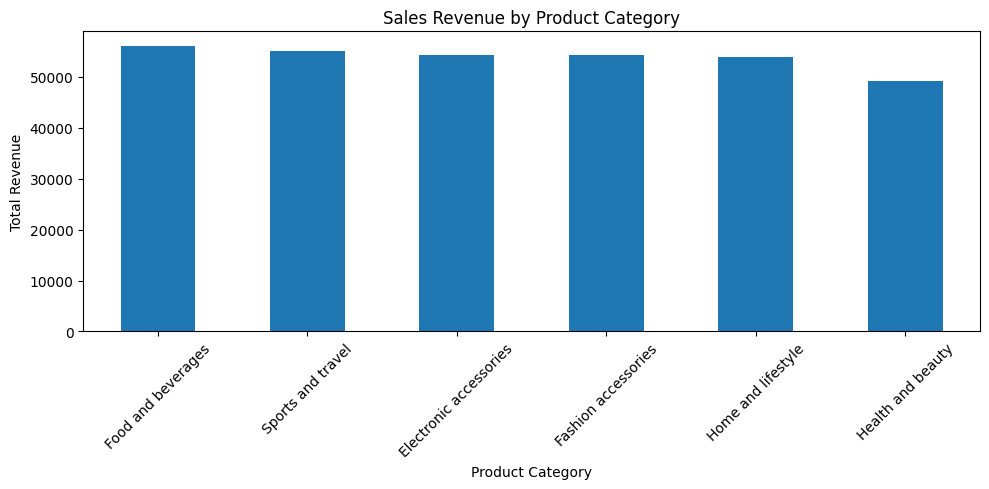

In [6]:

category_sales = (
    df_clean.groupby('Product line')['Total']
    .sum()
    .sort_values(ascending=False)
)

print(category_sales)

plt.figure(figsize=(10, 5))
category_sales.plot(kind='bar')
plt.title('Sales Revenue by Product Category')
plt.xlabel('Product Category')
plt.ylabel('Total Revenue')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


Branch-wise Revenue:
Branch
A    106200.3705
B    106197.6720
C    110568.7065
Name: Total, dtype: float64


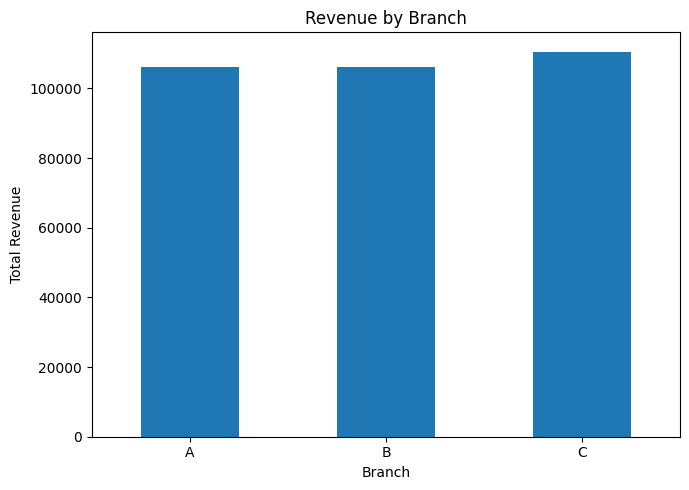

In [7]:

branch_sales = df_clean.groupby('Branch')['Total'].sum()

print("Branch-wise Revenue:")
print(branch_sales)

plt.figure(figsize=(7, 5))
branch_sales.plot(kind='bar')
plt.title('Revenue by Branch')
plt.xlabel('Branch')
plt.ylabel('Total Revenue')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


Payment
Ewallet        345
Cash           344
Credit card    311
Name: count, dtype: int64


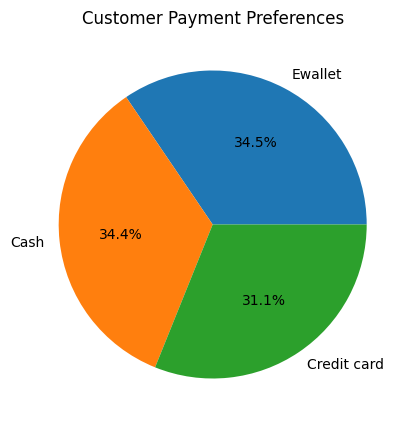

In [8]:

payment_counts = df_clean['Payment'].value_counts()

print(payment_counts)

plt.figure(figsize=(7, 5))
payment_counts.plot(kind='pie', autopct='%1.1f%%')
plt.title('Customer Payment Preferences')
plt.ylabel('')
plt.show()


Revenue by Customer Type:
Customer type
Member    164223.444
Normal    158743.305
Name: Total, dtype: float64


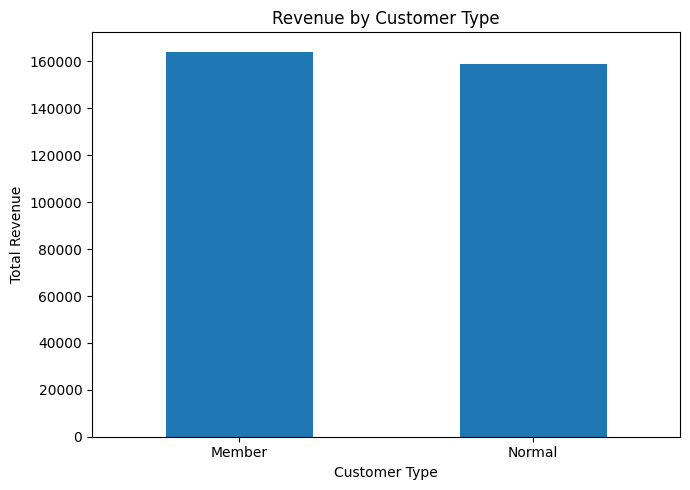

In [9]:

customer_sales = df_clean.groupby('Customer type')['Total'].sum()

print("Revenue by Customer Type:")
print(customer_sales)

plt.figure(figsize=(7, 5))
customer_sales.plot(kind='bar')
plt.title('Revenue by Customer Type')
plt.xlabel('Customer Type')
plt.ylabel('Total Revenue')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


Revenue by Gender:
Gender
Female    167882.925
Male      155083.824
Name: Total, dtype: float64


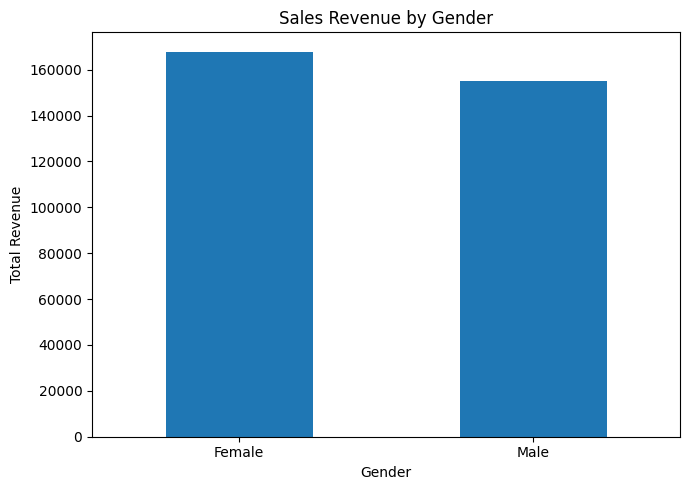

In [10]:

gender_sales = df_clean.groupby('Gender')['Total'].sum()

print("Revenue by Gender:")
print(gender_sales)

plt.figure(figsize=(7, 5))
gender_sales.plot(kind='bar')
plt.title('Sales Revenue by Gender')
plt.xlabel('Gender')
plt.ylabel('Total Revenue')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


Daily Sales:
Day
Monday       37899.0780
Tuesday      51482.2455
Wednesday    43731.1350
Thursday     45349.2480
Friday       43926.3405
Saturday     56120.8095
Sunday       44457.8925
Name: Total, dtype: float64


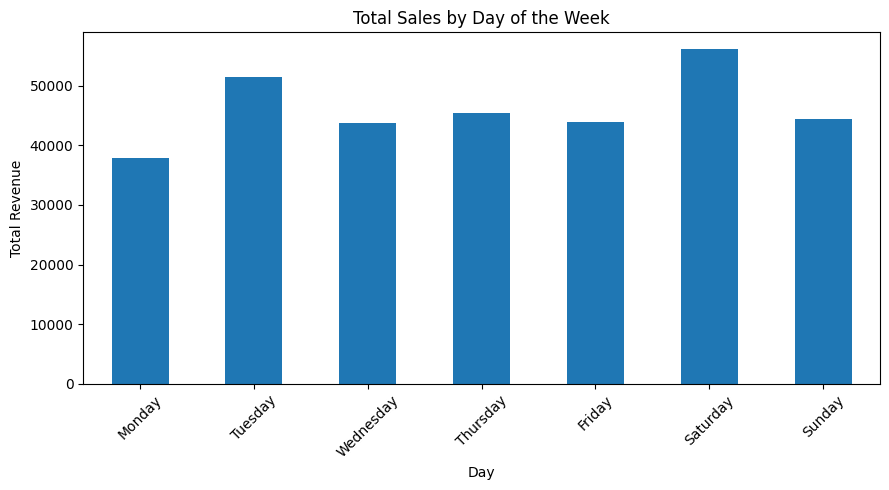

In [11]:

daily_sales = df_clean.groupby('Day')['Total'].sum()

day_order = [
    'Monday', 'Tuesday', 'Wednesday',
    'Thursday', 'Friday', 'Saturday', 'Sunday'
]

daily_sales = daily_sales.reindex(day_order)

print("Daily Sales:")
print(daily_sales)

plt.figure(figsize=(9, 5))
daily_sales.plot(kind='bar')
plt.title('Total Sales by Day of the Week')
plt.xlabel('Day')
plt.ylabel('Total Revenue')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


Hourly Sales:
Hour
10    31421.4810
11    30377.3295
12    26065.8825
13    34723.2270
14    30828.3990
15    31179.5085
16    25226.3235
17    24445.2180
18    26030.3400
19    39699.5130
20    22969.5270
Name: Total, dtype: float64


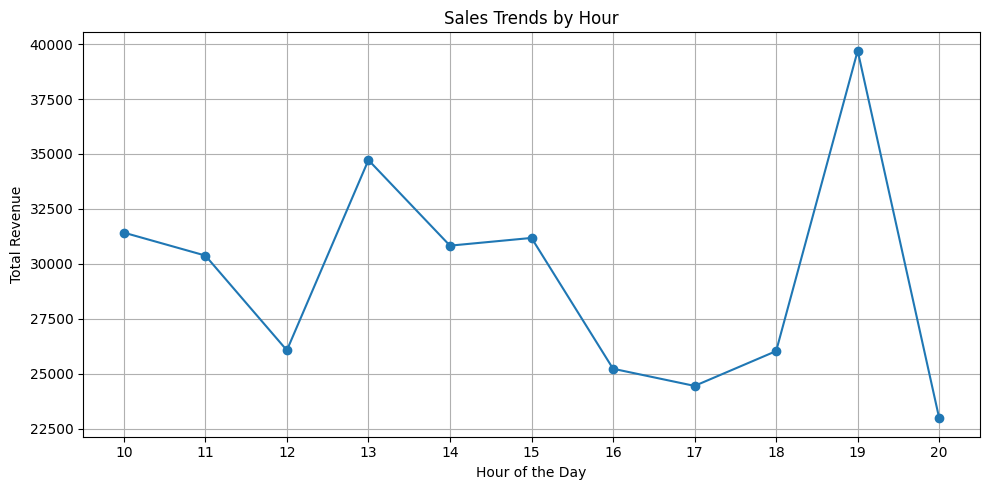

In [12]:

hourly_sales = df_clean.groupby('Hour')['Total'].sum()

print("Hourly Sales:")
print(hourly_sales)

plt.figure(figsize=(10, 5))
hourly_sales.plot(kind='line', marker='o')
plt.title('Sales Trends by Hour')
plt.xlabel('Hour of the Day')
plt.ylabel('Total Revenue')
plt.xticks(range(10, 21))
plt.grid(True)
plt.tight_layout()
plt.show()


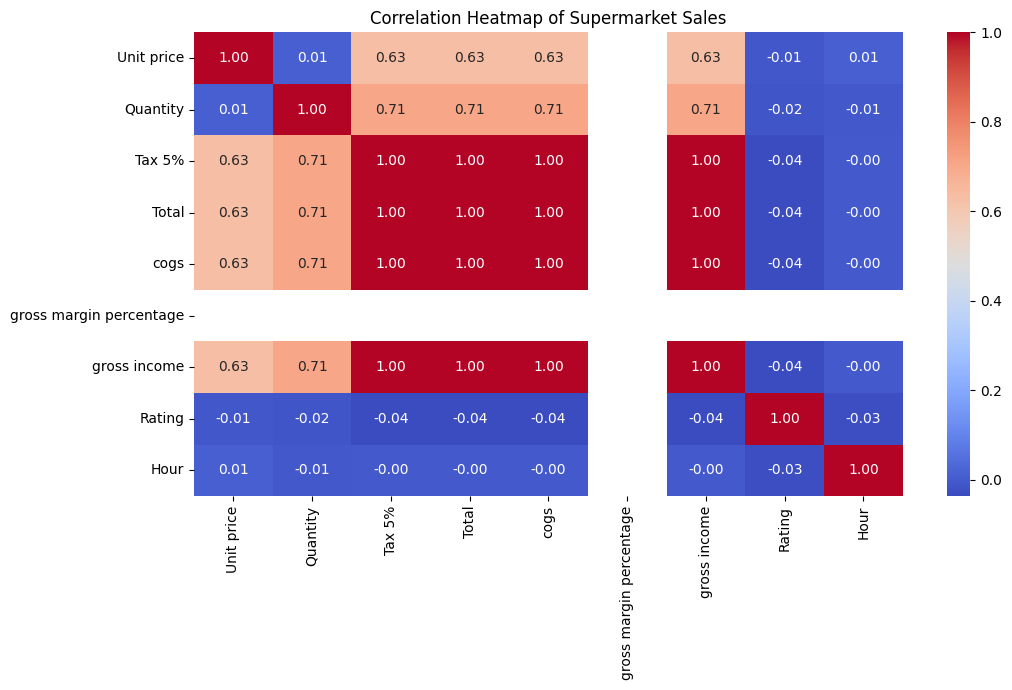

Correlation with Total Sales:
Total                      1.000000
Tax 5%                     1.000000
gross income               1.000000
cogs                       1.000000
Quantity                   0.705510
Unit price                 0.633962
Hour                      -0.002770
Rating                    -0.036442
gross margin percentage         NaN
Name: Total, dtype: float64


In [13]:

numeric_df = df_clean.select_dtypes(include=np.number)

correlation = numeric_df.corr()

plt.figure(figsize=(11, 7))
sns.heatmap(
    correlation,
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)
plt.title('Correlation Heatmap of Supermarket Sales')
plt.tight_layout()
plt.show()

print("Correlation with Total Sales:")
print(correlation['Total'].sort_values(ascending=False))


In [14]:

top_category = df_clean.groupby('Product line')['Total'].sum().idxmax()
top_branch = df_clean.groupby('Branch')['Total'].sum().idxmax()
top_payment = df_clean['Payment'].value_counts().idxmax()
top_customer = df_clean.groupby('Customer type')['Total'].sum().idxmax()
top_gender = df_clean.groupby('Gender')['Total'].sum().idxmax()
top_day = daily_sales.idxmax()
top_hour = hourly_sales.idxmax()

print("PROJECT KEY FINDINGS")
print("-" * 40)

print("Highest Revenue Product Category:", top_category)
print("Best Performing Branch:", top_branch)
print("Most Used Payment Method:", top_payment)
print("Highest Revenue Customer Type:", top_customer)
print("Highest Revenue Gender Group:", top_gender)
print("Highest Sales Day:", top_day)
print("Highest Sales Hour:", top_hour)


PROJECT KEY FINDINGS
----------------------------------------
Highest Revenue Product Category: Food and beverages
Best Performing Branch: C
Most Used Payment Method: Ewallet
Highest Revenue Customer Type: Member
Highest Revenue Gender Group: Female
Highest Sales Day: Saturday
Highest Sales Hour: 19


In [15]:

# Save cleaned dataset
df_clean.to_csv('cleaned_supermarket_sales.csv', index=False)

# Save analysis summaries
category_sales.to_csv('category_sales_summary.csv')
branch_sales.to_csv('branch_sales_summary.csv')
payment_counts.to_csv('payment_method_summary.csv')
customer_sales.to_csv('customer_type_summary.csv')
daily_sales.to_csv('daily_sales_summary.csv')
hourly_sales.to_csv('hourly_sales_summary.csv')
correlation.to_csv('sales_correlation_results.csv')

print("All project files saved successfully!")


All project files saved successfully!


In [16]:
from google.colab import files

files.download('cleaned_supermarket_sales.csv')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>